<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Spirulina-based-Microcapsules-Control-Release/blob/main/Note_2_Feed_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr

from sklearn.preprocessing import LabelEncoder

from sklearn.decomposition import PCA

from sklearn.model_selection import GroupShuffleSplit

In [ ]:
df = joblib.load(
    "dataset_clean.pkl"
)

spectral_cols = joblib.load(
    "spectral_cols.pkl"
)

metadata_cols = joblib.load(
    "metadata_cols.pkl"
)

target_cols = joblib.load(
    "target_cols.pkl"
)

print(df.shape)

(150, 607)


In [ ]:
release_corr = []

for wl in spectral_cols:

    r,_ = pearsonr(
        df[wl],
        df["Release"]
    )

    release_corr.append(r)

release_corr_df = pd.DataFrame({

    "Wavelength":
        spectral_cols,

    "Correlation":
        release_corr

})

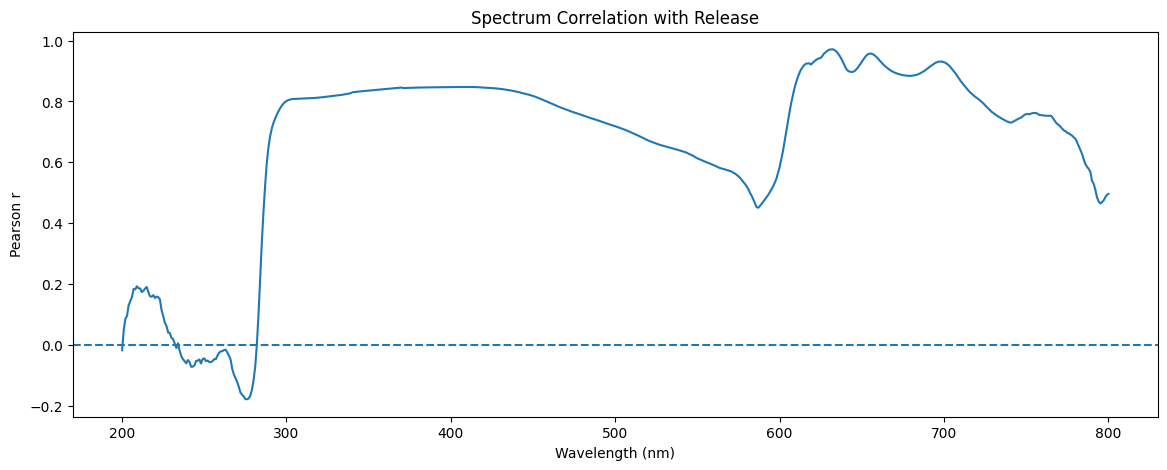

In [ ]:
plt.figure(figsize=(14,5))

plt.plot(

    release_corr_df["Wavelength"].str.replace('A_', '').astype(float),

    release_corr_df["Correlation"]

)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Wavelength (nm)"
)

plt.ylabel(
    "Pearson r"
)

plt.title(
    "Spectrum Correlation with Release"
)

plt.show()

In [ ]:
release_corr_df["AbsCorr"] = np.abs(
    release_corr_df["Correlation"]
)

top_release = release_corr_df.sort_values(

    "AbsCorr",

    ascending=False

).head(20)

display(top_release)

,Wavelength,Correlation,AbsCorr
432,A_632,0.971755,0.971755
431,A_631,0.971026,0.971026
433,A_633,0.970077,0.970077
430,A_630,0.969987,0.969987
429,A_629,0.966514,0.966514
434,A_634,0.966475,0.966475
428,A_628,0.962160,0.962160
435,A_635,0.961418,0.961418
455,A_655,0.957579,0.957579
427,A_627,0.957530,0.957530


In [ ]:
categorical_cols = [

    "Medium",

    "Spirulina_Size"
]

In [ ]:
encoders = {}

categorical_cols_fixed = [
    "Medium",
    "Spirulina_Size"
]

for col in categorical_cols_fixed:

    le = LabelEncoder()

    df[col] = le.fit_transform(
        df[col]
    )

    encoders[col] = le

# Explicitly set the classes for 'Medium' LabelEncoder to the desired string labels
# Assuming 0->'aquadest', 1->'sif', 2->'sgf' based on common practice
if 'Medium' in encoders:
    encoders['Medium'].classes_ = np.array(['Aquadest', 'SGF', 'SIF'])

In [ ]:
X_spectrum = df[
    spectral_cols
]

In [ ]:
pca = PCA()

pca.fit(
    X_spectrum
)

PCA()

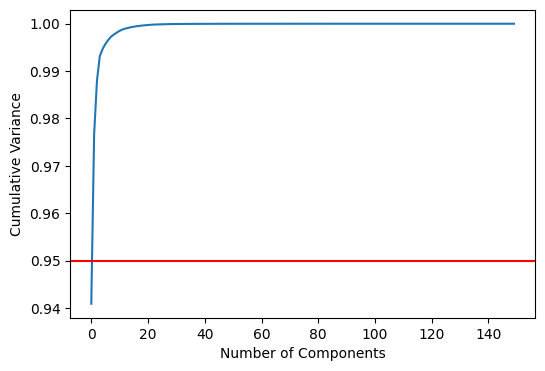

In [ ]:
cum_var = np.cumsum(

    pca.explained_variance_ratio_

)

plt.figure(figsize=(6,4))

plt.plot(
    cum_var
)

plt.axhline(
    0.95,
    color='red'
)

plt.xlabel(
    "Number of Components"
)

plt.ylabel(
    "Cumulative Variance"
)

plt.show()

In [ ]:
pca2 = PCA(
    n_components=2
)

pcs = pca2.fit_transform(
    X_spectrum
)

pca_df = pd.DataFrame({

    "PC1":pcs[:,0],

    "PC2":pcs[:,1],

    "Medium":df["Medium"]

})

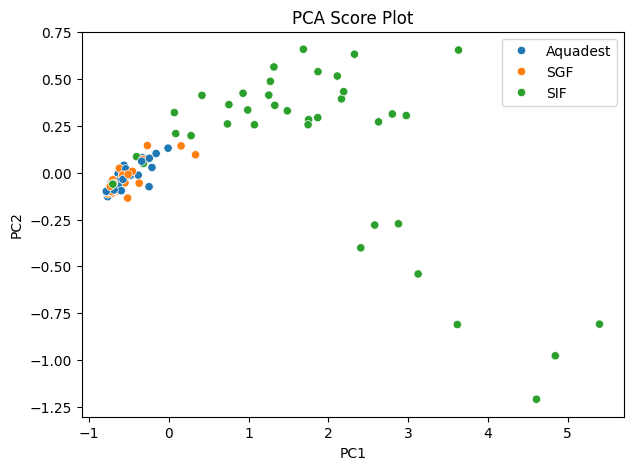

In [ ]:
plt.figure(figsize=(7,5))

sns.scatterplot(

    data=pca_df,

    x="PC1",

    y="PC2",

    hue=encoders['Medium'].inverse_transform(pca_df["Medium"])

)

plt.title(
    "PCA Score Plot"
)

plt.show()

In [ ]:
feature_cols = (

    metadata_cols +

    spectral_cols
)

In [ ]:
# Filter feature_cols
existing_features = [col for col in feature_cols if col in df.columns]
X = df[existing_features]

In [ ]:
y_release = df[
    "Release"
]

In [ ]:
groups = (

    encoders['Medium'].inverse_transform(df["Medium"]).astype(str)

    + "_"

    + encoders['Spirulina_Size'].inverse_transform(df["Spirulina_Size"]).astype(str)

    + "_"

    + df["Load"].astype(str)

)

In [ ]:
gss = GroupShuffleSplit(

    n_splits=1,

    test_size=0.2,

    random_state=42

)

In [ ]:
train_idx,test_idx = next(

    gss.split(

        X,

        y_release,

        groups

    )

)

In [ ]:
X_train_release = X.iloc[
    train_idx
]

X_test_release = X.iloc[
    test_idx
]

y_train_release = y_release.iloc[
    train_idx
]

y_test_release = y_release.iloc[
    test_idx
]

In [ ]:
joblib.dump(
    X_train_release,
    "X_train_release.pkl"
)

joblib.dump(
    X_test_release,
    "X_test_release.pkl"
)

joblib.dump(
    y_train_release,
    "y_train_release.pkl"
)

joblib.dump(
    y_test_release,
    "y_test_release.pkl"
)

['y_test_release.pkl']

In [ ]:
train_groups = groups.iloc[
    train_idx
]

test_groups = groups.iloc[
    test_idx
]

joblib.dump(
    train_groups,
    "train_groups.pkl"
)

joblib.dump(
    test_groups,
    "test_groups.pkl"
)

['test_groups.pkl']

In [ ]:
release_corr_df.to_excel(
    "Release_Correlation.xlsx",
    index=False
)